In [25]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from astropy.cosmology import FlatLambdaCDM
from set_style import set_style
import time
caesar_path = '/data20/TheThreeHundred/data_NewICs/catalogues/Caesar/GIZMO_7k/NewMDCLUSTER_0129/'

h = 0.678

with h5py.File('HaloID_track_Gizmo7k.hdf5','r') as f:
    z = f['z'][()]
    id_list = f['cluster_0129/id_list'][()]
cosmo = FlatLambdaCDM(H0=67.8, Om0=0.31)
lookback_time = cosmo.lookback_time(z).value

In [26]:
clusid = 129

with h5py.File('HaloID_track_Gizmo7k.hdf5','r') as f:
    main_haloID = f[f'cluster_{clusid:04d}/id_list'][()]

nsnaps = 129

L_FIR = np.zeros(nsnaps)
Mstar = np.zeros(nsnaps)
SFR_central = np.zeros(nsnaps)
bh_fedd = np.zeros(nsnaps)
bh_mdot = np.zeros(nsnaps)
bh_mass = np.zeros(nsnaps)

snaps = np.arange(128,-1, -1)

for i, snap in enumerate(snaps):

    #print(f'Processing snapshot {snap}')

    try:
    
        # identify index for central galaxy properties
        with h5py.File(caesar_path+f'Caesar_C200_snap_{snap:03d}.hdf5') as f:
            HaloID = f['halo_data/AHF_haloID'][()]
            parent_halo = f['galaxy_data/parent_halo_index'][()]
            central = f['galaxy_data/central'][()]
    
        index_halo = np.argwhere(HaloID == main_haloID[i])
        index_gal = np.argwhere((parent_halo == index_halo)&(central == True))[0][0]
    
        with h5py.File(caesar_path+f'Caesar_C200_snap_{snap:03d}.hdf5') as f:
            #total_mass = f['galaxy_data/dicts/masses.total'][()]
            L_fir_temp = f['galaxy_data/dicts/photometry.L_FIR'][index_gal]
            bh_mass_temp = f['galaxy_data/dicts/masses.bh'][index_gal]
            bhmdot_temp = f['galaxy_data/bhmdot'][index_gal]
            bh_fedd_temp = f['galaxy_data/bh_fedd'][index_gal]
            stellar_mass_temp = f['galaxy_data/dicts/masses.stellar'][index_gal]
            sfr_temp = f['galaxy_data/sfr'][index_gal]

        L_FIR[i] = L_fir_temp
        Mstar[i] = stellar_mass_temp
        SFR_central[i] = sfr_temp
        bh_fedd[i] = bh_fedd_temp
        bh_mdot[i] = bhmdot_temp
        bh_mass[i] = bh_mass_temp

    except:
        print(f'failed at snapshot {snap}')
        continue



failed at snapshot 15
failed at snapshot 14
failed at snapshot 13
failed at snapshot 12
failed at snapshot 11
failed at snapshot 10
failed at snapshot 9
failed at snapshot 8
failed at snapshot 7
failed at snapshot 6
failed at snapshot 5
failed at snapshot 4
failed at snapshot 3
failed at snapshot 2
failed at snapshot 1
failed at snapshot 0


## COMPUTING CENTRAL GALAXY PROPERTIES

In [27]:

def compute_central_galaxy(cluster=1, fout='central_gal_properties_all.hdf5'):

    
    with h5py.File('HaloID_track_Gizmo7k.hdf5','r') as f:
        main_haloID = f[f'cluster_{cluster:04d}/id_list'][()]
    
    nsnaps = 129
    
    L_FIR = np.zeros(nsnaps)
    Mstar = np.zeros(nsnaps)
    SFR_central = np.zeros(nsnaps)
    bh_fedd = np.zeros(nsnaps)
    bh_mdot = np.zeros(nsnaps)
    bh_mass = np.zeros(nsnaps)
    
    snaps = np.arange(128,-1, -1)
    
    for i, snap in enumerate(snaps):
    
        #print(f'Processing snapshot {snap}')
    
        try:
        
            # identify index for central galaxy properties
            with h5py.File(caesar_path+f'Caesar_C200_snap_{snap:03d}.hdf5') as f:
                HaloID = f['halo_data/AHF_haloID'][()]
                parent_halo = f['galaxy_data/parent_halo_index'][()]
                central = f['galaxy_data/central'][()]
        
            index_halo = np.argwhere(HaloID == main_haloID[i])
            index_gal = np.argwhere((parent_halo == index_halo)&(central == True))[0][0]
        
            with h5py.File(caesar_path+f'Caesar_C200_snap_{snap:03d}.hdf5') as f:
                #total_mass = f['galaxy_data/dicts/masses.total'][()]
                bh_mass_temp = f['galaxy_data/dicts/masses.bh'][index_gal]
                bhmdot_temp = f['galaxy_data/bhmdot'][index_gal]
                bh_fedd_temp = f['galaxy_data/bh_fedd'][index_gal]
                stellar_mass_temp = f['galaxy_data/dicts/masses.stellar'][index_gal]
                sfr_temp = f['galaxy_data/sfr'][index_gal]
        
            Mstar[i] = stellar_mass_temp
            SFR_central[i] = sfr_temp
            bh_fedd[i] = bh_fedd_temp
            bh_mdot[i] = bhmdot_temp
            bh_mass[i] = bh_mass_temp
    
        except:
            #print(f'failed at snapshot {snap}')
            continue

    time.sleep(np.random.rand())
    with h5py.File(fout, 'a') as f2:

        if f'cluster_{cluster:04d}' in f2.keys(): del f2[f'cluster_{cluster:04d}']
        
        f2.create_dataset(f'cluster_{cluster:04d}/Mstar', data = Mstar)
        f2.create_dataset(f'cluster_{cluster:04d}/SFR_central', data = SFR_central)
        f2.create_dataset(f'cluster_{cluster:04d}/bh_fedd', data = bh_fedd)
        f2.create_dataset(f'cluster_{cluster:04d}/bh_mdot', data = bh_mdot)
        f2.create_dataset(f'cluster_{cluster:04d}/bh_mass', data = bh_mass)
                          
    return 0




In [1]:
"""
Far-infrared / total-infrared luminosities of massive (proto)cluster cores at high z.
 
Format of every list:  (label, z, value [Lsun], err_lo, err_hi, kind)
    kind: "val" (value +/- err), "lo" (lower limit), "up" (upper limit)
 
Two lists, kept separate because the integration ranges differ:
    OBS_LIR   : total IR,  rest-frame 8-1000 um (Miller+18 uses 8-1100 um)
    OBS_LFIR  : far-IR,    rest-frame 42.5-122.5 um (Walter+12, Riechers+14)
                           or 42-500 um (Hill+20) -- see BAND below
All values are already in solar luminosities in the source papers, so no unit
conversion was needed; to_lsun() is provided for any future value quoted in W
or erg/s.  L_sun = 3.828e26 W .
 
Values flagged DERIVED in the comments were computed here from published
numbers (sums of members, rescalings); everything else is quoted directly.
"""

import numpy as np
 
LSUN_W = 3.828e26          # W
LSUN_ERG = 3.828e33        # erg/s
 
 
def to_lsun(L, unit="W"):
    """Convert a luminosity in W or erg/s to Lsun."""
    return np.asarray(L) / {"W": LSUN_W, "erg/s": LSUN_ERG}[unit]
 
 
def _sum_asym(vals, lo, hi):
    """Sum of members; errors added LINEARLY because the per-source errors are
    dominated by a common Tdust/template systematic (fully correlated)."""
    return float(np.sum(vals)), float(np.sum(lo)), float(np.sum(hi))
 
 
# ---------------------------------------------------------------------------
# Member tables used for the DERIVED sums
# ---------------------------------------------------------------------------
# Oteo+18 Table 1, L_IR(8-1000) [1e11 Lsun], ALESS template scaled to 2 mm
DRC_MEMBERS_LIR = {"DRC-1": 161.5, "DRC-2": 55.2, "DRC-3": 50.9, "DRC-4": 26.5,
                   "DRC-5": 22.5, "DRC-6": 21.5, "DRC-7": 13.4, "DRC-8": 4.2,
                   "DRC-9": 3.2, "DRC-10": 3.1, "DRC-11": 3.0}   # DRC-5: no line
 
# Hill+20 Table 2, L_FIR(42-500) [1e10 Lsun], greybody Td=39.6 K, beta=2
#   (value, -err, +err); non-detections (<5-9e10) are omitted
SPT_CORE_LFIR = {"C1": (1030, 300, 420), "C2": (210, 60, 80), "C3": (890, 260, 370),
                 "C4": (570, 170, 240), "C5": (420, 130, 180), "C6": (620, 180, 260),
                 "C7": (82, 25, 34), "C8": (490, 150, 210), "C9": (180, 50, 80),
                 "C10": (180, 60, 80), "C11": (39, 18, 21), "C12": (29, 10, 13),
                 "C13": (180, 50, 80), "C14": (51, 27, 31), "C15": (36, 14, 17),
                 "C17": (110, 60, 80), "C18": (17, 9, 10), "C19": (21, 8, 10)}
SPT_NORTH_LFIR = {"N1": (1730, 510, 720), "N2": (650, 270, 400)}
 
# Casey 2016 Table 4 (SSA22), L_IR [Lsun], 35 K MBB + MIR power law
SSA22_MEMBERS_LIR = [(1.1e13, 0.5e13, 0.9e13), (4.5e12, 2.0e12, 3.7e12),
                     (3.5e12, 1.6e12, 2.9e12), (1.8e12, 0.8e12, 1.4e12),
                     (1.4e13, 0.6e13, 1.2e13), (4.3e12, 1.9e12, 3.5e12),
                     (5.1e12, 2.3e12, 4.1e12), (9.1e12, 4.1e12, 7.5e12),
                     (1.8e12, 0.8e12, 1.5e12), (1.7e12, 0.7e12, 1.4e12),
                     (1.8e12, 0.8e12, 1.5e12), (1.3e12, 0.6e12, 1.1e12)]
 
# ---- derived sums ----------------------------------------------------------
_drc_all = sum(DRC_MEMBERS_LIR.values()) * 1e11                       # 3.65e13
_drc_conf = (sum(DRC_MEMBERS_LIR.values()) - DRC_MEMBERS_LIR["DRC-5"]) * 1e11
_drc_sfr_per_L = 6500. / _drc_all       # Oteo's own SFR/L_IR ratio (Salpeter)
 
_c = np.array(list(SPT_CORE_LFIR.values()), float) * 1e10
_spt_core = _sum_asym(_c[:, 0], _c[:, 1], _c[:, 2])
_n = np.array(list(SPT_NORTH_LFIR.values()), float) * 1e10
_spt_north = _sum_asym(_n[:, 0], _n[:, 1], _n[:, 2])
_spt_cn = tuple(a + b for a, b in zip(_spt_core, _spt_north))
_ALMA_RESOLVED = 0.55                    # Hill+20: 55+/-5 % of LABOCA 870um flux
 
_s = np.array(SSA22_MEMBERS_LIR)
_ssa22 = _sum_asym(_s[:, 0], _s[:, 1], _s[:, 2])
 
_gn20 = np.array([[1.86e13, 0.09e13], [8.0e12, 0.7e12], [6.9e12, 1.0e12]])
_gn20_sum = _gn20[:, 0].sum()
_gn20_err = float(np.sqrt((_gn20[:, 1] ** 2).sum()))   # independent DL07 fits
 
# ---------------------------------------------------------------------------
# OBS_LIR : total infrared, 8-1000 um   [Lsun]
# ---------------------------------------------------------------------------
OBS_LIR = [
    # label, z, value [Lsun], err_lo, err_hi, kind
    # --- DRC, z=4.002 (Oteo+18; ALESS template, Arp220 template gives x1.36)
    ("DRC (Oteo+18, 11 ALMA comps)",       4.002, _drc_all, 0, 0, "val"),     # DERIVED sum = 3.65e13 (paper quotes ~3.7e13)
    ("DRC (Oteo+18, LABOCA A+B)",          4.002, 8900. / _drc_sfr_per_L, 0, 0, "val"),  # DERIVED from SFR=8900
    ("DRC (Oteo+18, full LABOCA field)",   4.002, 14400. / _drc_sfr_per_L, 0, 0, "up"),  # DERIVED; members unconfirmed
    # --- SPT2349-56, z=4.30 (Miller+18; CIGALE fit to SPIRE+LABOCA, 8-1100 um,
    #     whole 110 mJy LABOCA structure, core + northern component)
    ("SPT2349-56 (Miller+18, LABOCA total)", 4.304, 8.0e13, 1.0e13, 1.0e13, "val"),
    # --- GN20 group, z=4.05 (Tan+14, DL07 fits; GN20.2a hosts a radio AGN)
    ("GN20 group (Tan+14, 3 SMGs)",        4.055, _gn20_sum, _gn20_err, _gn20_err, "val"),  # DERIVED sum = 3.35e13
    ("GN20 (Tan+14)",                      4.055, 1.86e13, 0.09e13, 0.09e13, "val"),
    # --- HDF850.1 overdensity, z=5.18 (single DSFG)
    ("HDF850.1 (Walter+12)",               5.183, 8.7e12, 1.0e12, 1.0e12, "val"),
    ("HDF850.1 (Sun+24, lensing-corr.)",   5.183, 5.0e12, 2.0e12, 2.0e12, "val"),  # systematic-dominated error
    # --- AzTEC-3 overdensity, z=5.30 (single DSFG); Capak+11 quote a RANGE
    #     2.2-11e13, stored at the geometric mean with errors spanning the range
    ("AzTEC-3 (Capak+11, range)",          5.298, np.sqrt(2.2e13 * 11e13),
     np.sqrt(2.2e13 * 11e13) - 2.2e13, 11e13 - np.sqrt(2.2e13 * 11e13), "val"),
    # --- SPT0311-58, z=6.90 (Marrone+18; intrinsic, lens-corrected, CIGALE)
    ("SPT0311-58 (Marrone+18, E+W)",       6.900, 4.6e12 + 33e12,
     float(np.hypot(1.2e12, 7e12)), float(np.hypot(1.2e12, 7e12)), "val"),  # DERIVED sum = 3.76e13
    # --- SSA22, z=3.09 (Casey16 Table 4; 12 DSFGs; below the z~4 range)
    ("SSA22 (Casey16, 12 DSFGs)",          3.090, *_ssa22, "val"),          # DERIVED sum
]
 
# ---------------------------------------------------------------------------
# OBS_LFIR : far infrared   [Lsun]   (integration range in BAND)
# ---------------------------------------------------------------------------
OBS_LFIR = [
    # --- SPT2349-56 (Hill+20, 42-500 um, Td=39.6 K greybody)
    ("SPT2349-56 (Hill+20, core 23 gal.)",   4.303, *_spt_core, "val"),    # DERIVED sum of detections = 5.18e13
    ("SPT2349-56 (Hill+20, core+north)",     4.303, *_spt_cn, "val"),      # DERIVED
    ("SPT2349-56 (Hill+20, /0.55 LABOCA)",   4.303,
     _spt_cn[0] / _ALMA_RESOLVED, _spt_cn[1] / _ALMA_RESOLVED,
     _spt_cn[2] / _ALMA_RESOLVED, "val"),                                  # DERIVED, crude flux-fraction scaling
    # --- HDF850.1 (Walter+12, 42-122 um)
    ("HDF850.1 (Walter+12)",                 5.183, 6.5e12, 1.0e12, 1.0e12, "val"),
    # --- AzTEC-3 (Riechers+14, 42.5-122.5 um, optically thick MBB)
    ("AzTEC-3 (Riechers+14)",                5.298, 1.10e13, 0.21e13, 0.22e13, "val"),
    # --- SPT0311-58 (Jarugula+21, intrinsic)
    ("SPT0311-58 (Jarugula+21, E+W)",        6.900, 16e12 + 2.7e12,
     float(np.hypot(4e12, 0.4e12)), float(np.hypot(4e12, 0.4e12)), "val"),  # DERIVED sum = 1.87e13
]
 
BAND = {  # rest-frame integration range per label (um)
    **{lab: "8-1000" for lab, *_ in OBS_LIR},
    "SPT2349-56 (Miller+18, LABOCA total)": "8-1100",
    "SPT2349-56 (Hill+20, core 23 gal.)": "42-500",
    "SPT2349-56 (Hill+20, core+north)": "42-500",
    "SPT2349-56 (Hill+20, /0.55 LABOCA)": "42-500",
    "HDF850.1 (Walter+12)": "42-122",            # same label in both lists:
    "AzTEC-3 (Riechers+14)": "42.5-122.5",       # BAND_LFIR below disambiguates
    "SPT0311-58 (Jarugula+21, E+W)": "FIR (Jarugula+21)",
}
BAND_LFIR = {"HDF850.1 (Walter+12)": "42-122"}
BAND_LIR = {"HDF850.1 (Walter+12)": "8-1000"}
 
# L_IR/L_FIR ratio used by Hill+20 (mean of ALPINE). Only for quick, approximate
# conversion of OBS_LFIR to an L_IR scale; it is SED-dependent.
LIR_OVER_LFIR = 1.628
 
 
def lfir_as_lir(obs=OBS_LFIR, ratio=LIR_OVER_LFIR):
    return [(lab + " [xL_IR/L_FIR]", z, v * ratio, lo * ratio, hi * ratio, k)
            for lab, z, v, lo, hi, k in obs]
 
 
def write_hdf5(fname="obs_lir.h5"):
    """One group per reference label, following the project's HDF5 practice:
    datasets z, L, err_lo, err_hi with a `unit` attribute; kind and band as attrs."""
    import h5py
    with h5py.File(fname, "w") as f:
        for gname, obs, bands in (("L_IR", OBS_LIR, BAND_LIR),
                                  ("L_FIR", OBS_LFIR, BAND_LFIR)):
            top = f.create_group(gname)
            for lab, z, v, lo, hi, kind in obs:
                g = top.create_group(lab)
                for key, val, unit in (("z", z, ""), ("L", v, "Lsun"),
                                       ("err_lo", lo, "Lsun"), ("err_hi", hi, "Lsun")):
                    d = g.create_dataset(key, data=float(val))
                    d.attrs["unit"] = unit
                g.attrs["kind"] = kind
                g.attrs["band_um"] = bands.get(lab, BAND.get(lab, ""))
        f.attrs["Lsun_W"] = LSUN_W
    return fname
 
 
if __name__ == "__main__":
    for name, obs, bands in (("OBS_LIR", OBS_LIR, BAND_LIR), ("OBS_LFIR", OBS_LFIR, BAND_LFIR)):
        print(f"\n{name}")
        print(f"{'label':42s} {'z':>6s} {'L [Lsun]':>10s} {'-err':>9s} {'+err':>9s} kind  band[um]")
        for lab, z, v, lo, hi, k in obs:
            print(f"{lab:42s} {z:6.3f} {v:10.3e} {lo:9.2e} {hi:9.2e} {k:4s}  "
                  f"{bands.get(lab, BAND.get(lab, ''))}")
    print("\nwrote", write_hdf5())


OBS_LIR
label                                           z   L [Lsun]      -err      +err kind  band[um]
DRC (Oteo+18, 11 ALMA comps)                4.002  3.650e+13  0.00e+00  0.00e+00 val   8-1000
DRC (Oteo+18, LABOCA A+B)                   4.002  4.998e+13  0.00e+00  0.00e+00 val   8-1000
DRC (Oteo+18, full LABOCA field)            4.002  8.086e+13  0.00e+00  0.00e+00 up    8-1000
SPT2349-56 (Miller+18, LABOCA total)        4.304  8.000e+13  1.00e+13  1.00e+13 val   8-1100
GN20 group (Tan+14, 3 SMGs)                 4.055  3.350e+13  1.52e+12  1.52e+12 val   8-1000
GN20 (Tan+14)                               4.055  1.860e+13  9.00e+11  9.00e+11 val   8-1000
HDF850.1 (Walter+12)                        5.183  8.700e+12  1.00e+12  1.00e+12 val   8-1000
HDF850.1 (Sun+24, lensing-corr.)            5.183  5.000e+12  2.00e+12  2.00e+12 val   8-1000
AzTEC-3 (Capak+11, range)                   5.298  4.919e+13  2.72e+13  6.08e+13 val   8-1000
SPT0311-58 (Marrone+18, E+W)                6.900

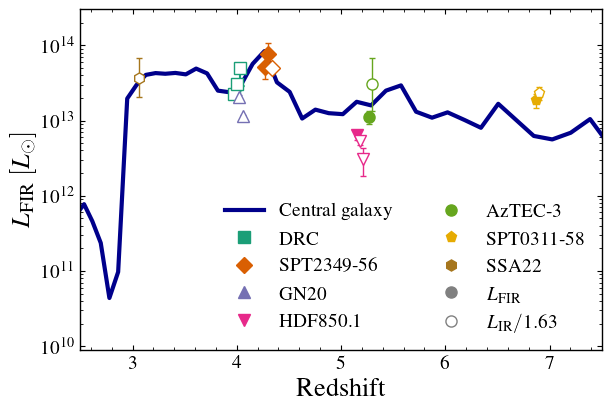

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from obs_lir import OBS_LIR, OBS_LFIR, LIR_OVER_LFIR

# ---------------------------------------------------------------------------
# Observations: filled = native L_FIR, open = L_IR(8-1000um) rescaled to the
# FIR scale by 1/1.628 (Hill+20 ALPINE ratio). Set CONVERT_LIR=False to plot
# L_IR as published instead.
# ---------------------------------------------------------------------------
CONVERT_LIR = True
SKIP = ("/0.55",)          # drop the crude LABOCA-rescaled SPT2349 point

OBJ_STYLE = {              # one colour/marker per object
    "DRC":        dict(c="#1b9e77", m="s"),
    "SPT2349-56": dict(c="#d95f02", m="D"),
    "GN20":       dict(c="#7570b3", m="^"),
    "HDF850.1":   dict(c="#e7298a", m="v"),
    "AzTEC-3":    dict(c="#66a61e", m="o"),
    "SPT0311-58": dict(c="#e6ab02", m="p"),
    "SSA22":      dict(c="#a6761d", m="h"),
}

def _obj(label):
    for k in OBJ_STYLE:
        if label.startswith(k):
            return k
    return None

def add_obs_lfir(ax, convert_lir=CONVERT_LIR, ms=8, offset=0.03):
    sets = [(OBS_LFIR, 1.0, True)]
    sets.append((OBS_LIR, 1.0 / LIR_OVER_LFIR if convert_lir else 1.0, False))
    seen = {}
    for obs, scale, filled in sets:
        for label, z, v, lo, hi, kind in obs:
            if any(s in label for s in SKIP):
                continue
            key = _obj(label)
            st = OBJ_STYLE.get(key, dict(c="k", m="o"))
            # small z-offset so several estimates of one object don't overlap
            n = seen.get(key, 0); seen[key] = n + 1
            zz = z + offset * (n - 1)
            v, lo, hi = v * scale, lo * scale, hi * scale
            mfc = st["c"] if filled else "white"
            yerr = None if (lo == 0 and hi == 0) else [[lo], [hi]]
            if kind in ("lo", "up"):
                ax.errorbar(zz, v, yerr=0.4 * v, uplims=(kind == "up"),
                            lolims=(kind == "lo"), fmt=st["m"], ms=ms,
                            color=st["c"], mfc=mfc, mec=st["c"], capsize=0, zorder=5)
            else:
                ax.errorbar(zz, v, yerr=yerr, fmt=st["m"], ms=ms, color=st["c"],
                            mfc=mfc, mec=st["c"], elinewidth=1, capsize=2, zorder=5)
    # legend: one entry per object + filled/open key
    h = [plt.Line2D([], [], ls="", marker=s["m"], color=s["c"], ms=ms, label=k)
         for k, s in OBJ_STYLE.items() if k in seen]
    h += [plt.Line2D([], [], ls="", marker="o", color="gray", ms=ms, label=r"$L_{\rm FIR}$"),
          plt.Line2D([], [], ls="", marker="o", color="gray", mfc="white", ms=ms,
                     label=(r"$L_{\rm IR}/1.63$" if convert_lir else r"$L_{\rm IR}$"))]
    return h


# ---------------------------------------------------------------------------
set_style('mnras', Hratio=0.75)
fs = 17
fig, ax = plt.subplots(1, 1, figsize=(6,4))

ax.set_xlabel('Redshift', fontsize=fs+2)
ax.set_ylabel(r'$ L_{\rm FIR} \ [L_\odot]$', fontsize=fs+2)
ax.set_yscale('log')
ax.set_xlim([2.5, 7.5])
ax.set_ylim([9e9, 3e14])

ax.tick_params(labelsize=fs-3)

l_sim, = ax.plot(z, L_FIR, lw=3, color='darkblue', label='Central galaxy')
h_obs = add_obs_lfir(ax)

ax.legend(handles=[l_sim] + h_obs, loc='lower right', fontsize=fs-3, ncol=2, frameon=False)

plt.savefig('plots/L_FIR_obs.png', dpi=400)